In [1]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

before_path = r"E:\flood_practice\2021-07-06-00_00_2021-07-06-23_59_Sentinel-1_IW_VV_VH_VV_(Raw).tiff"
after_path = r"E:\flood_practice\2021-07-18-00_00_2021-07-18-23_59_Sentinel-1_IW_VV_VH_VV_(Raw).tiff"

with rasterio.open(before_path) as src:
    before = src.read(1).astype('float32')
with rasterio.open(after_path) as src:
    after = src.read(1).astype('float32')

In [2]:
valid_mask=(np.isfinite(before)&np.isfinite(after)&(before>0)&(after>0))

before_db = np.full(before.shape, np.nan, dtype='float32')
after_db = np.full(after.shape, np.nan, dtype='float32')

before_db[valid_mask] = 10 * np.log10(before[valid_mask])
after_db[valid_mask] = 10 * np.log10(after[valid_mask])

In [3]:
print(
    "2021-07-12:",
    np.nanpercentile(before_db, [2, 50, 98])
)

print(
    "2021-07-18:",
    np.nanpercentile(after_db, [2, 50, 98])
)

2021-07-12: [-21.11352539  -9.45691013   0.27450457]
2021-07-18: [-23.86775589  -9.64788103   0.52452284]


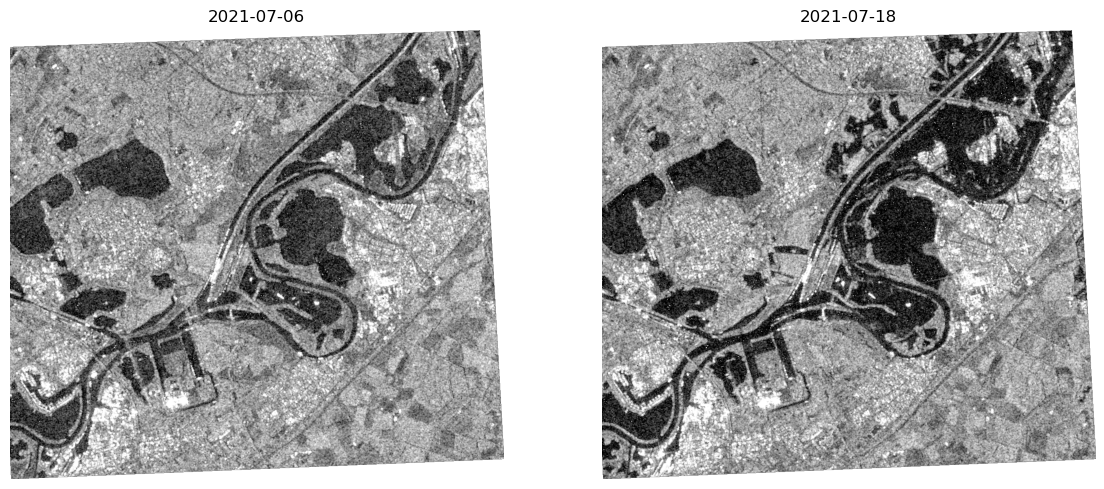

In [4]:
all_db = np.concatenate([
    before_db[valid_mask],
    after_db[valid_mask]
])

vmin, vmax = np.nanpercentile(all_db, [2, 98])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(before_db, cmap='gray', vmin=vmin, vmax=vmax)
axes[0].set_title('2021-07-06')
axes[0].axis('off')

axes[1].imshow(after_db, cmap='gray', vmin=vmin, vmax=vmax)
axes[1].set_title('2021-07-18')
axes[1].axis('off')

plt.show()

In [5]:
change_db = after_db - before_db

In [6]:
print('change 2 to 98%:', np.nanpercentile(change_db,[2,50,98]))

change 2 to 98%: [-10.21354198  -0.48680496   7.0810994 ]


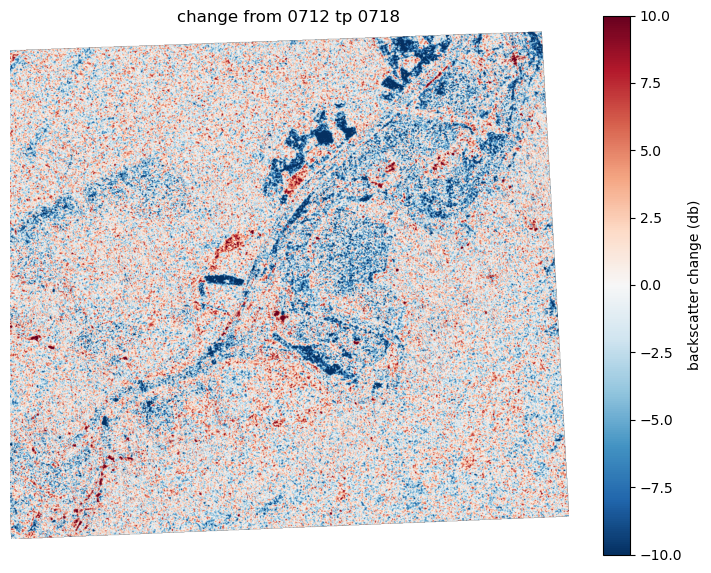

In [7]:
plt.figure(figsize=(9, 7))
plt.imshow(change_db,cmap='RdBu_r',vmin=-10,vmax=10)
plt.colorbar(label="backscatter change (db)")
plt.title('change from 0712 tp 0718')
plt.axis('off')
plt.show()

In [8]:
flood_place = (valid_mask & (change_db<-5) & (after_db<-15))

In [9]:
print('flood_place:',np.sum(flood_place))
print('percentage:', np.sum(flood_place)/np.sum(valid_mask)*100)

flood_place: 110055
percentage: 8.285127948784352


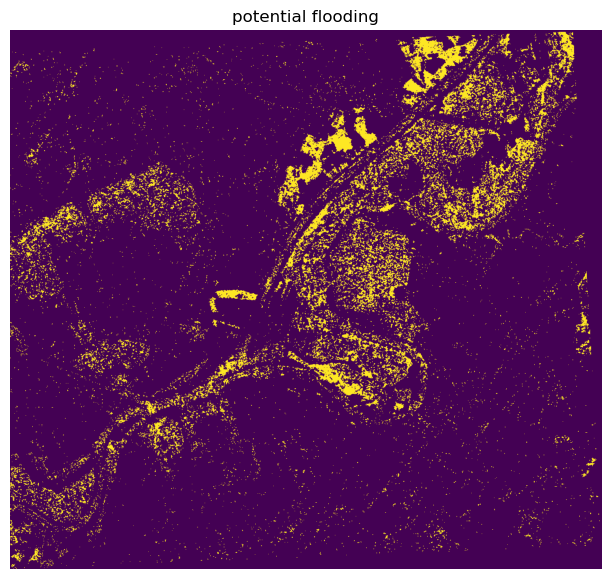

In [10]:
plt.figure(figsize=(9, 7))
plt.imshow(flood_place)
plt.title('potential flooding')
plt.axis('off')
plt.show()

In [11]:
water_place = (valid_mask & (before_db < -15))
finalflood_place = (flood_place &(~water_place))

In [12]:
print('flood_place:',np.sum(finalflood_place))
print('percentage:', np.sum(finalflood_place)/np.sum(valid_mask)*100)

flood_place: 77667
percentage: 5.8469041151990755


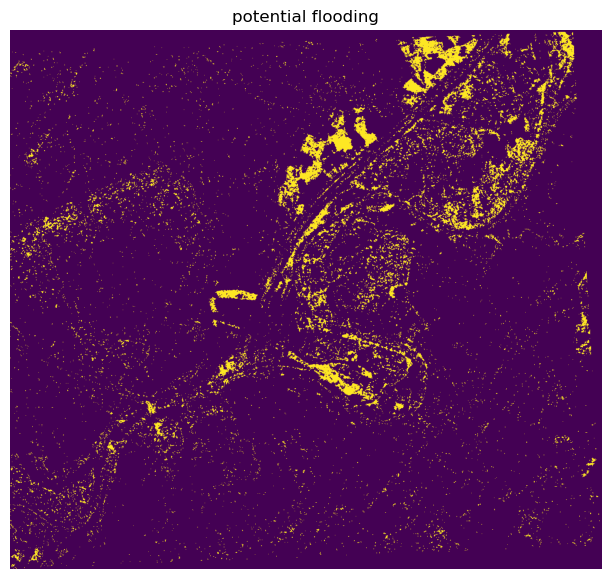

In [13]:
plt.figure(figsize=(9, 7))
plt.imshow(finalflood_place)
plt.title('potential flooding')
plt.axis('off')
plt.show()

In [14]:
from scipy.ndimage import label
import numpy as np

labels, num_features = label(finalflood_place, structure=np.ones((3, 3)))
sizes = np.bincount(labels.ravel())
keep = sizes  >= 20
keep[0] = False
cleaned_flood = keep[labels]

Original pixels: 77667
Cleaned pixels: 46966
Number of patches: 9964


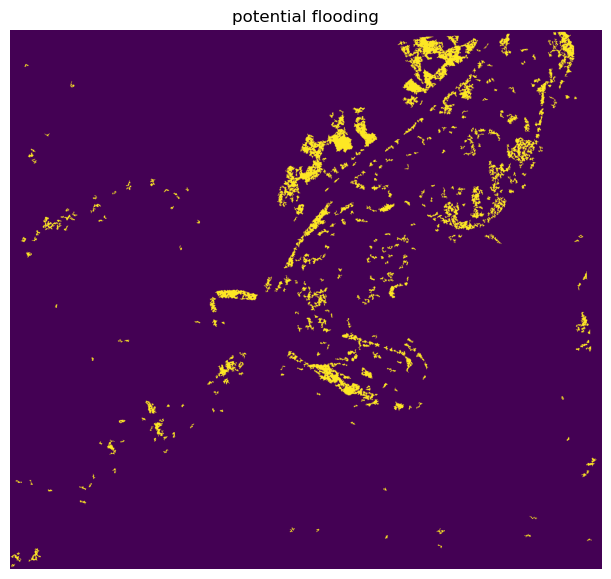

In [15]:
print("Original pixels:", np.sum(finalflood_place))
print("Cleaned pixels:", np.sum(cleaned_flood))
print("Number of patches:", num_features)


plt.figure(figsize=(9, 7))
plt.imshow(cleaned_flood)
plt.title('potential flooding')
plt.axis('off')
plt.show()

In [16]:
with rasterio.open(after_path) as src:
    pixel_width = abs(src.transform.a)
    pixel_height = abs(src.transform.e)

print('pixel_width:',pixel_width)
print('pixel_height:',pixel_height)

pixel_width: 6.943795030399971
pixel_height: 7.225576340649326


In [17]:
pixel_area = pixel_height * pixel_width

In [18]:
flood_pixels = np.sum(cleaned_flood)

flood_place_m2 = flood_pixels * pixel_area
flood_place_km2 = flood_place_m2/1000000
print("flood_place_m2",flood_place_m2)
print("flood_place_km2",flood_place_km2)

flood_place_m2 2356421.4117239676
flood_place_km2 2.3564214117239675


In [19]:
import rasterio
import numpy as np

output_path = r"E:\flood_practice\flood_baseline.tif"

flood_output = np.full(cleaned_flood.shape,255,dtype='uint8')
# 255 - no data 1- flood 0 - no flood

flood_output[valid_mask] = 0
flood_output[cleaned_flood] = 1

with rasterio.open(after_path) as src:
    profile = src.profile.copy()

profile.update(dtype='uint8',count=1, nodata=255, compress='lzw')

with rasterio.open(output_path, 'w', **profile) as dst:
    dst.write(flood_output, 1)

print('saved', output_path)

saved E:\flood_practice\flood_baseline.tif


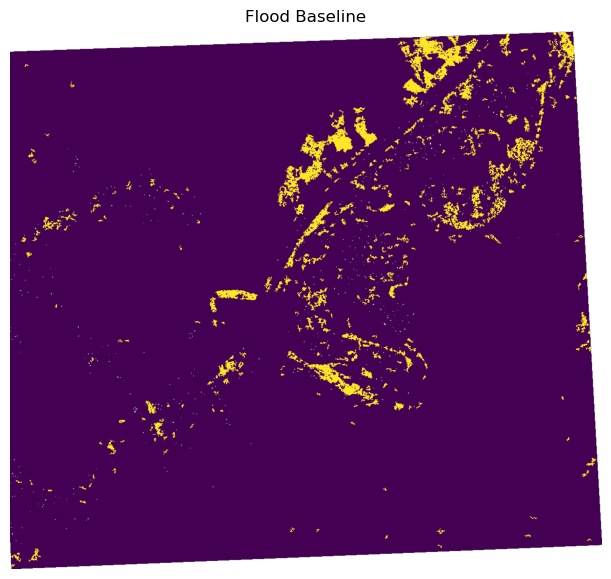

In [20]:
with rasterio.open(output_path) as src:
    flood_check = src.read(1)

display = np.ma.masked_where(
    flood_check == 255,
    flood_check
)

plt.figure(figsize=(9, 7))
plt.imshow(display)
plt.title("Flood Baseline")
plt.axis("off")
plt.show()

In [21]:
import geopandas as gpd

training = gpd.read_file(r"E:\flood_practice\train_flood_samplings.shp")
print(training.head())
print(training['Id'].value_counts())
print(training.crs)

   Id                                           geometry
0   1  POLYGON ((705524.345 5676398.85, 705586.84 567...
1   1  POLYGON ((705312.239 5676230.302, 705387.991 5...
2   1  POLYGON ((703515.021 5673775.935, 703653.269 5...
3   1  POLYGON ((703005.707 5673210.517, 703189.169 5...
4   1  POLYGON ((706548.891 5677571.113, 706707.971 5...
Id
1    18
0    15
Name: count, dtype: int64
EPSG:32631


In [22]:
from rasterio.features import rasterize
with rasterio.open(after_path) as src:
    transform = src.transform
    shape = (src.height, src.width)

class_shapes = [(geom, int(class_id))for geom, class_id in zip(training.geometry,training['Id'])]
class_raster = rasterize(shapes=class_shapes,out_shape=shape,transform=transform,fill=255,dtype='uint8')

In [23]:
train_mask = (valid_mask & (class_raster != 255))

In [24]:
x = np.column_stack([before_db[train_mask],after_db[train_mask],change_db[train_mask]])

In [25]:
y = class_raster[train_mask]

In [40]:
# 1. 给每个 polygon 一个独立编号
training = training.copy()

training["poly_id"] = np.arange(
    1,
    len(training) + 1,
    dtype=np.int32
)

# 2. 准备 polygon geometry + polygon ID
polygon_shapes = [
    (geom, int(poly_id))
    for geom, poly_id in zip(
        training.geometry,
        training["poly_id"]
    )
]

# 3. 把 polygon 编号转换成 raster
polygon_id_raster = rasterize(
    shapes=polygon_shapes,
    out_shape=shape,
    transform=transform,
    fill=0,
    dtype="int32"
)

# 4. 只提取训练区域里的 polygon 编号
groups = polygon_id_raster[train_mask]

# 5. 检查结果
print("x shape:", x.shape)
print("y shape:", y.shape)
print("groups shape:", groups.shape)
print("Polygon IDs:", np.unique(groups))
print("Unassigned training pixels:", np.sum(groups == 0))

x shape: (168446, 3)
y shape: (168446,)
groups shape: (168446,)
Polygon IDs: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33]
Unassigned training pixels: 0


In [41]:
groups = polygon_id_raster[train_mask]

In [43]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(x, y, groups=groups)
)
X_train = x[train_idx]
X_test = x[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

groups_train = groups[train_idx]
groups_test = groups[test_idx]

In [44]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=-1,
                       random_state=42)

In [46]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

y_pred = rf.predict(X_test)

print(confusion_matrix(y_test, y_pred))

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)
feature_names = [
    "before_db",
    "after_db",
    "change_db"
]

for name, importance in zip(
    feature_names,
    rf.feature_importances_
):
    print(name, importance)

[[45104   476]
 [  669   567]]
              precision    recall  f1-score   support

           0       0.99      0.99      0.99     45580
           1       0.54      0.46      0.50      1236

    accuracy                           0.98     46816
   macro avg       0.76      0.72      0.74     46816
weighted avg       0.97      0.98      0.97     46816

before_db 0.1934992353375248
after_db 0.41589619021591173
change_db 0.39060457444656355


In [47]:
X_all = np.column_stack([
    before_db[valid_mask],
    after_db[valid_mask],
    change_db[valid_mask]
])

In [49]:
pred_all = rf.predict(X_all)
rf_flood = np.full(
    before_db.shape,
    255,
    dtype="uint8"
)

rf_flood[valid_mask] = pred_all.astype("uint8")

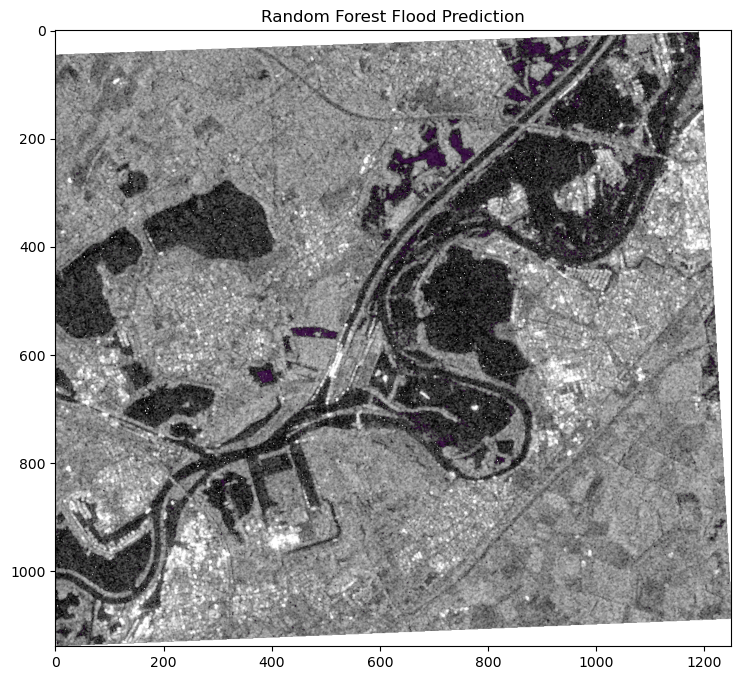

In [50]:
rf_display = np.ma.masked_where(
    rf_flood != 1,
    rf_flood
)

plt.figure(figsize=(10, 8))

plt.imshow(
    after_db,
    cmap="gray",
    vmin=-25,
    vmax=5
)

plt.imshow(
    rf_display,
    alpha=0.6
)

plt.title("Random Forest Flood Prediction")

plt.show()

In [51]:
rf_flood_pixels = np.sum(rf_flood == 1)

rf_flood_m2 = (
    rf_flood_pixels * pixel_area
)

rf_flood_km2 = (
    rf_flood_m2 / 1_000_000
)

print("RF flood pixels:", rf_flood_pixels)
print("RF flood area km²:", rf_flood_km2)

RF flood pixels: 25341
RF flood area km²: 1.2714319932397278


In [52]:
output_path = r"E:\flood_practice\flood_random_forest.tif"

with rasterio.open(after_path) as src:
    profile = src.profile.copy()

profile.update(
    dtype="uint8",
    count=1,
    nodata=255,
    compress="lzw"
)

with rasterio.open(
    output_path,
    "w",
    **profile
) as dst:
    dst.write(rf_flood, 1)

print("Saved:", output_path)

Saved: E:\flood_practice\flood_random_forest.tif


In [53]:
baseline_mask = cleaned_flood
rf_mask = (rf_flood == 1)

both_flood = (
    baseline_mask &
    rf_mask
)

baseline_only = (
    baseline_mask &
    (~rf_mask)
)

rf_only = (
    (~baseline_mask) &
    rf_mask
)
print(
    "Both flood:",
    np.sum(both_flood)
)

print(
    "Baseline only:",
    np.sum(baseline_only)
)

print(
    "RF only:",
    np.sum(rf_only)
)
print(
    "Both flood area km²:",
    np.sum(both_flood)
    * pixel_area
    / 1_000_000
)

print(
    "Baseline only area km²:",
    np.sum(baseline_only)
    * pixel_area
    / 1_000_000
)

print(
    "RF only area km²:",
    np.sum(rf_only)
    * pixel_area
    / 1_000_000
)

Both flood: 19137
Baseline only: 27829
RF only: 6204
Both flood area km²: 0.9601591908223303
Baseline only area km²: 1.396262220901637
RF only area km²: 0.3112728024173976


In [55]:
comparison = np.zeros(
    baseline_mask.shape,
    dtype="uint8"
)

comparison[both_flood] = 1
comparison[baseline_only] = 2
comparison[rf_only] = 3

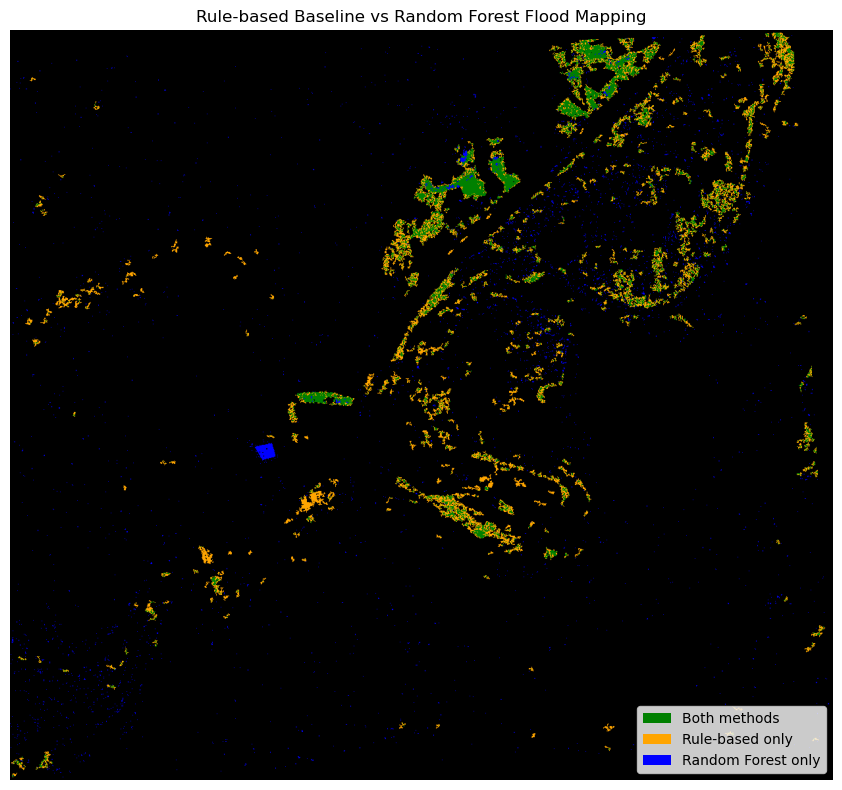

In [58]:
import matplotlib.pyplot as plt
import numpy as np

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# 0 = neither
# 1 = both methods
# 2 = baseline only
# 3 = RF only

comparison = np.zeros(
    baseline_mask.shape,
    dtype="uint8"
)

comparison[both_flood] = 1
comparison[baseline_only] = 2
comparison[rf_only] = 3
colors = [
    "black",      # 0 neither
    "green",      # 1 both
    "orange",     # 2 baseline only
    "blue"        # 3 RF only
]

cmap = ListedColormap(colors)

plt.figure(figsize=(10, 8))

plt.imshow(
    comparison,
    cmap=cmap,
    vmin=0,
    vmax=3
)

plt.title(
    "Rule-based Baseline vs Random Forest Flood Mapping"
)

legend_elements = [
    Patch(
        facecolor="green",
        label="Both methods"
    ),
    Patch(
        facecolor="orange",
        label="Rule-based only"
    ),
    Patch(
        facecolor="blue",
        label="Random Forest only"
    )
]

plt.legend(
    handles=legend_elements,
    loc="lower right"
)

plt.axis("off")

plt.tight_layout()

plt.savefig(
    r"E:\flood_practice\baseline_vs_rf_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()